# When should you book a flight in India?

About 300k economy and business fares between Delhi, Mumbai, Bangalore, Kolkata, Hyderabad and Chennai, scraped from EaseMyTrip for travel dates between 11 Feb and 31 Mar 2022 ([Kaggle](https://www.kaggle.com/datasets/shubhambathwal/flight-price-prediction)).

I worked from the raw `economy.csv` / `business.csv` files instead of the pre-cleaned version on Kaggle. So the first part of this notebook is cleaning.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

In [2]:
economy = pd.read_csv("data/economy.csv").assign(cabin="Economy")
business = pd.read_csv("data/business.csv").assign(cabin="Business")

df = pd.concat([economy, business], ignore_index=True).rename(columns={"from": "source", "to": "destination"})
df.shape

(300261, 12)

In [3]:
df.head()

,date,airline,ch_code,num_code,dep_time,source,time_taken,stop,arr_time,destination,price,cabin
0,11-02-2022,SpiceJet,SG,8709,18:55,Delhi,02h 10m,non-stop,21:05,Mumbai,"5,953",Economy
1,11-02-2022,SpiceJet,SG,8157,06:20,Delhi,02h 20m,non-stop,08:40,Mumbai,"5,953",Economy
2,11-02-2022,AirAsia,I5,764,04:25,Delhi,02h 10m,non-stop,06:35,Mumbai,"5,956",Economy
3,11-02-2022,Vistara,UK,995,10:20,Delhi,02h 15m,non-stop,12:35,Mumbai,"5,955",Economy
4,11-02-2022,Vistara,UK,963,08:50,Delhi,02h 20m,non-stop,11:10,Mumbai,"5,955",Economy


In [4]:
df["stop"].value_counts().head(6)

stop
1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t\t\t\t\t\t\t             243603
non-stop                                                                36044
2+-stop                                                                 13288
1-stop\n\t\t\t\t\t\t\t\t\t\t\t\tVia IXU\n\t\t\t\t\t\t\t\t\t\t\t\t        1839
1-stop\n\t\t\t\t\t\t\t\t\t\t\t\tVia IDR\n\t\t\t\t\t\t\t\t\t\t\t\t        1398
1-stop\n\t\t\t\t\t\t\t\t\t\t\t\tVia Patna\n\t\t\t\t\t\t\t\t\t\t\t\t       674
Name: count, dtype: int64

In [5]:
df[~df["time_taken"].str.fullmatch(r"\d+h \d+m")]

,date,airline,ch_code,num_code,dep_time,source,time_taken,stop,arr_time,destination,price,cabin
96486,26-02-2022,GO FIRST,G8,146,05:45,Bangalore,1.03h m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,09:10,Mumbai,"5,177",Economy
104676,26-02-2022,GO FIRST,G8,146,05:45,Bangalore,1.02h m,2+-stop,08:00,Kolkata,"5,177",Economy
111315,26-02-2022,GO FIRST,G8,146,05:45,Bangalore,1.03h m,2+-stop,09:30,Hyderabad,"4,337",Economy
154007,25-02-2022,GO FIRST,G8,517,20:45,Hyderabad,1.01h m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t...,21:50,Delhi,"6,132",Economy


## Cleaning

What needs fixing:
- `stop` had tabs, newlines and layover airports mixed in (`"1-stop
			Via IDR..."`), 37 variants for what is really 0 / 1 / 2+ stops
- `price` was text with commas, `time_taken` was text like `02h 10m`
- 4 rows had a broken duration (`1.03h m`) and 2 rows were exact duplicates, dropped
- `days_left` isn't in the raw files, so I rebuilt it as travel date minus 10 Feb 2022 (matches the column in Kaggle's cleaned version)

In [6]:
df = df.drop_duplicates()
df = df[df["time_taken"].str.fullmatch(r"\d+h \d+m")]

hm = df["time_taken"].str.extract(r"(\d+)h (\d+)m").astype(int)
df["duration_hrs"] = hm[0] + hm[1] / 60
df["price"] = df["price"].str.replace(",", "").astype(int)
df["date"] = pd.to_datetime(df["date"], format="%d-%m-%Y")
df["days_left"] = (df["date"] - pd.Timestamp("2022-02-10")).dt.days
df["stops"] = df["stop"].str.extract(r"(non-stop|1-stop|2\+-stop)")[0].map({"non-stop": 0, "1-stop": 1, "2+-stop": 2})
df["dep_hour"] = df["dep_time"].str[:2].astype(int)
df["route"] = df["source"] + "-" + df["destination"]

df = df.drop(columns=["stop", "time_taken", "ch_code", "num_code"])
df.shape

(300255, 13)

In [7]:
df.isna().sum().sum()

np.int64(0)

In [8]:
df.groupby("cabin")["price"].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
cabin,,,,,,,,
Business,93487.0,52540.0,12969.0,12000.0,45185.0,53164.0,60396.0,123071.0
Economy,206768.0,6571.0,3743.0,1105.0,4173.0,5772.0,7746.0,42349.0


## Comparing like with like

Kolkata–Chennai and Mumbai–Hyderabad are different markets, so a plain average mostly reflects which routes are in the group. For the economy analysis I divide every fare by the median fare on its route: 1.0 = normal price for that route, 1.3 = 30% above.

In [9]:
eco = df[df["cabin"] == "Economy"].copy()
eco["rel_price"] = eco["price"] / eco.groupby("route")["price"].transform("median")

## 1. How far ahead should you book?

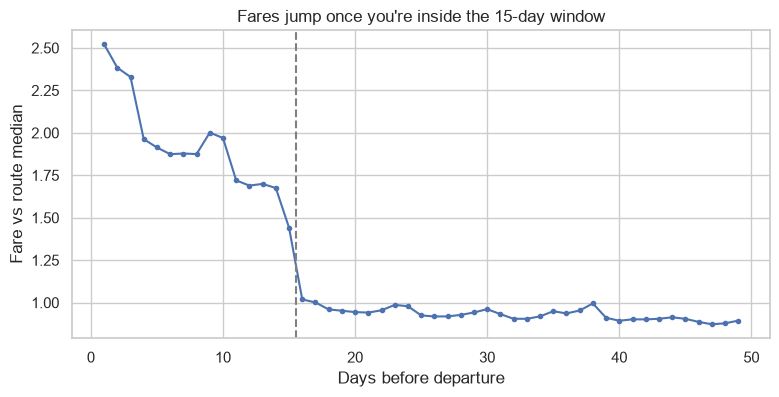

In [10]:
curve = eco.groupby("days_left")["rel_price"].median()

ax = curve.plot(figsize=(9, 4), marker="o", ms=3)
ax.axvline(15.5, ls="--", c="grey")
ax.set(xlabel="Days before departure", ylabel="Fare vs route median",
       title="Fares jump once you're inside the 15-day window")
plt.savefig("images/booking_window.png", dpi=120, bbox_inches="tight")

In [11]:
eco.groupby(pd.cut(eco["days_left"], [0, 3, 7, 15, 30, 49]), observed=True)["rel_price"].median().round(2)

days_left
(0, 3]      2.39
(3, 7]      1.91
(7, 15]     1.74
(15, 30]    0.96
(30, 49]    0.91
Name: rel_price, dtype: float64

Booked 16 or more days out, fares sit at or slightly below the route's normal level (0.9–1.0x). Inside 15 days they jump to about 1.7x, and in the last 3 days to about 2.4x. On a typical route (median economy fare ₹5,809) that's roughly ₹5,500 vs ₹14,000 for the same trip.

The change between day 16 and day 15 is a step, not a slope. My guess is that the cheaper fare classes close at a fixed advance-purchase cutoff rather than prices creeping up with demand.

## 2. Which airline is cheapest?

StarAir and Trujet have under 100 flights each, so I left them out of the table.

In [12]:
airlines = (eco.groupby("airline")
              .agg(flights=("price", "size"), median_fare=("price", "median"), rel_price=("rel_price", "median"))
              .query("flights > 1000")
              .sort_values("rel_price"))
airlines

,flights,median_fare,rel_price
airline,,,
AirAsia,16098,3276.0,0.595161
Indigo,43120,4453.0,0.815778
GO FIRST,23173,5336.0,0.970496
SpiceJet,9011,5654.0,0.999846
Air India,47994,6082.0,1.055831
Vistara,67270,6461.0,1.109657


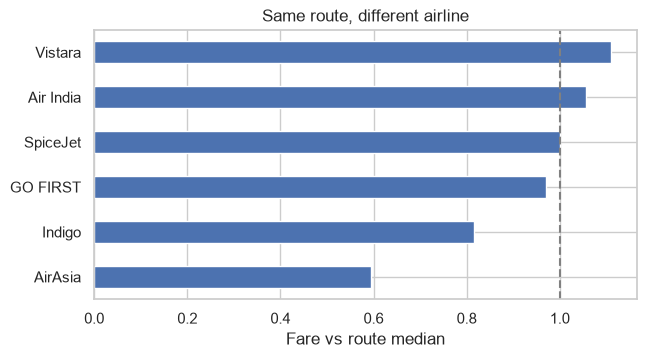

In [13]:
ax = airlines["rel_price"].plot.barh(figsize=(7, 3.5))
ax.axvline(1, c="grey", ls="--")
ax.set(xlabel="Fare vs route median", ylabel="", title="Same route, different airline")
plt.savefig("images/airlines.png", dpi=120, bbox_inches="tight")

AirAsia is about 40% below the route median and IndiGo about 18% below. The full-service carriers, Air India and Vistara, charge 6–11% above. SpiceJet and Go First sit right around the median.

This is a 2022 snapshot. Go First stopped flying in May 2023 and Vistara merged into Air India in November 2024.

## 3. Does departure time matter?

In [14]:
slots = pd.cut(eco["dep_hour"], bins=[0, 5, 9, 12, 17, 21, 24], right=False,
               labels=["Before 5am", "5-9am", "9am-12pm", "12-5pm", "5-9pm", "After 9pm"])
eco.groupby(slots, observed=True)["rel_price"].agg(["size", "median"]).round(2)

,size,median
dep_hour,,
Before 5am,3353,0.82
5-9am,52546,1.00
9am-12pm,40169,1.05
12-5pm,44471,1.00
5-9pm,48661,1.00
After 9pm,17568,0.96


Departure time matters far less than when you book or which airline you pick. Flights before 5am are about 18% cheaper, but they're under 2% of all flights. Late-morning departures (9am–12pm) carry a small premium of about 5%.

## 4. Non-stop vs connecting flights

In [15]:
eco.groupby("stops").agg(flights=("price", "size"), rel_price=("rel_price", "median"), duration_hrs=("duration_hrs", "median")).round(2)

,flights,rel_price,duration_hrs
stops,,,
0,27942,0.62,2.25
1,166623,1.00,11.33
2,12203,1.44,12.75


Could this just be budget airlines flying the non-stops? Checking within each airline:

In [16]:
eco.pivot_table(index="airline", columns="stops", values="rel_price", aggfunc="median").loc[airlines.index].round(2)

stops,0,1,2
airline,,,
AirAsia,0.60,0.60,0.61
Indigo,0.64,0.86,1.21
GO FIRST,0.46,0.98,1.05
SpiceJet,0.76,1.03,NaN
Air India,0.53,1.05,1.86
Vistara,0.67,1.10,1.57


I expected connecting flights to be the cheap option, but it's the other way round. Non-stops are about 38% below the route median, one-stop flights are at the median, and 2+ stops are about 44% above. The pattern holds inside every airline except AirAsia, where the price barely changes with the number of stops.

## 5. Is weekend travel more expensive?

Travel date and `days_left` move together here (`days_left` is counted from one fixed date), so comparing weekdays across all rows would mix in the booking-window effect. I only use flights 16+ days out, where the curve above is flat.

In [17]:
early = eco[eco["days_left"] >= 16]
weekend = early["date"].dt.dayofweek >= 5

print(early.groupby(weekend)["rel_price"].median().rename({False: "weekday", True: "weekend"}).round(3))
stats.mannwhitneyu(early.loc[weekend, "rel_price"], early.loc[~weekend, "rel_price"])

date
weekday    0.919
weekend    0.970
Name: rel_price, dtype: float64


MannwhitneyuResult(statistic=np.float64(2649643919.5), pvalue=np.float64(4.4396941845930416e-237))

Weekend flights cost about 5% more than weekday ones even when booked early (0.97x vs 0.92x of the route median). The Mann-Whitney test gives p < 0.001, but with ~150k fares almost any gap will be significant, so the 5% is the more useful number.

## 6. What does business class cost?

In [18]:
by_cabin = df.pivot_table(index=["airline", "route"], columns="cabin", values="price", aggfunc="median").dropna()
(by_cabin["Business"] / by_cabin["Economy"]).groupby("airline").describe().round(1)

,count,mean,std,min,25%,50%,75%,max
airline,,,,,,,,
Air India,30.0,8.6,1.0,6.9,8.2,8.6,9.2,10.9
Vistara,30.0,9.2,1.9,6.7,7.5,9.0,10.4,13.2


Only Air India and Vistara sell business class on these routes. On the same airline and route, business costs about 9x economy (median 8.6x for Air India, 9.0x for Vistara), ranging from 6.7x to 13.2x depending on the route.

## Takeaways

If I were booking one of these routes:
1. **Book at least 16 days ahead.** Nothing else here saves as much: about 1.7x the normal fare inside the window vs about 0.95x outside it.
2. **For the lowest price, pick AirAsia or IndiGo non-stop.** Non-stop is usually both faster and cheaper.
3. **Fly midweek if your dates are flexible.** Weekends are about 5% dearer.
4. **Don't chase a 5am flight just to save money.** Time of day barely moves the fare.

## Limitations

- Each `days_left` value is a different set of flights, not the same flight tracked over time, so the booking curve is a cross-section rather than a price history.
- Early 2022 was still a COVID-recovery period, and the airline line-up has changed since then.
- Only EaseMyTrip listings and only six metro cities are covered.
- I used medians throughout because fares are heavily right-skewed.